# LLM Fine Tuning · Lesson 4 · Your first fine-tune: SFT with LoRA

Lessons 1 to 3 chose the task (a question about a table in, one SQLite query out), the model (Qwen2.5-1.5B-Instruct)
and the data (sql-create-context, split by table). This lab trains the model with supervised fine-tuning (SFT) and
LoRA, and measures what changed.

Six questions are asked, each answered by a measurement:

1. **How good is the model before any training?** Two baselines on 500 held-out examples: a zero-shot prompt and a
   three-shot prompt.
2. **How do we train it?** TRL's `SFTTrainer` with a LoRA adapter, loss on the answer only, on a T4.
3. **What did training change?** The same 500 examples, plus memory, adapter size and trainable parameters.
4. **What is still wrong?** The failures of the tuned model, sorted into causes.
5. **Is it worth it?** All three systems side by side.
6. **What do we keep?** The adapter.

**Run it:** Runtime → Change runtime type → T4 GPU, then Runtime → Run all. It takes about 25 minutes on a T4: about
15 minutes of training and 10 of data preparation and generation.
The lesson that explains every result is at [docs.recohut.com](https://docs.recohut.com/courses/llm-fine-tuning/2-train/04-sft-with-lora).

## 0. Install, load and rebuild the lesson 3 splits

In [1]:
# Pinned versions, so the code matches the lesson it was written for.
%pip install -q transformers==4.51.3 peft==0.15.2 accelerate==1.6.0 trl==0.19.1 datasets==3.6.0

pip may report dependency conflicts with packages Colab preinstalls, such as `gradio`. This lab does not use them,
so the warning can be ignored.

In [2]:
import gc
import json
import os
import random
import re
import sqlite3
import time
import urllib.request

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import peft
import torch
import transformers
import trl
from datasets import Dataset
from peft import LoraConfig, PeftModel
from transformers import AutoModelForCausalLM, AutoTokenizer, set_seed
from trl import SFTConfig, SFTTrainer

%config InlineBackend.figure_formats = ['svg']
assert torch.cuda.is_available(), "Choose Runtime -> Change runtime type -> T4 GPU."

SEED = 42
set_seed(SEED)
MODEL_ID = "Qwen/Qwen2.5-1.5B-Instruct"
DEVICE = "cuda"
DTYPE = torch.float16        # a T4 has no bfloat16 (lesson 2)
N_TEST = 500                 # held-out examples every system is scored on
N_VAL = 500                  # validation examples, used for the loss curve only
N_TRAIN = 8000               # training examples, chosen in section 2: about 15 minutes on a T4
GB = 1e9
print("transformers", transformers.__version__, "| trl", trl.__version__, "| peft", peft.__version__)
print("GPU:", torch.cuda.get_device_name(0))

transformers 4.51.3 | trl 0.19.1 | peft 0.15.2
GPU: Tesla T4


The data is rebuilt here with the same code and the same seed as lesson 3, so this lab runs on its own: drop gold
queries that fail in SQLite, drop exact duplicates, then split **by table** (5% test, 5% validation, the rest
training). The counts should match lesson 3: 69,170 training examples.

In [3]:
# Pinned to the same commit of the dataset as lesson 3.
URL = ("https://huggingface.co/datasets/b-mc2/sql-create-context/resolve/"
       "9d80a6a118b838d9defc3798d659a54a2ac2ff37/sql_create_context_v4.json")
data = pd.DataFrame(json.load(urllib.request.urlopen(URL)))


def runs(context, sql):
    """Return None if the query runs against the schema, or the SQLite error message."""
    con = sqlite3.connect(":memory:")
    try:
        for statement in context.split(";"):
            if statement.strip():
                con.execute(statement)
        con.execute(sql)
        return None
    except sqlite3.Error as e:
        return str(e)
    finally:
        con.close()


norm = lambda s: re.sub(r"\s+", " ", s.strip().lower())
data["error"] = [runs(c, a) for c, a in zip(data["context"], data["answer"])]

# A split group is one named table. WikiSQL's re-used names (table_name_N) are groups of one.
table = data["context"].str.extract(r"CREATE TABLE (\w+)")[0].fillna("")
named = ~table.str.fullmatch(r"table_name_\d+")
data["group"] = np.where(named, table, "row" + data.index.astype(str))

clean = data[data["error"].isna()].drop_duplicates(["question", "context", "answer"]).reset_index(drop=True)
uniq = np.random.default_rng(SEED).permutation(clean["group"].unique())
n = len(uniq)
split_of = {u: ("test" if i < 0.05 * n else "validation" if i < 0.10 * n else "train") for i, u in enumerate(uniq)}
clean["split"] = clean["group"].map(split_of)
print(clean["split"].value_counts().to_string())

SYSTEM = "You write SQLite queries. Answer with one SQL query and nothing else."


def messages(r):
    """One example in conversational prompt-completion form, as TRL's SFTTrainer expects it."""
    return {
        "prompt": [{"role": "system", "content": SYSTEM},
                   {"role": "user", "content": f"Schema:\n{r['context']}\n\nQuestion: {r['question']}"}],
        "completion": [{"role": "assistant", "content": r["answer"]}],
    }


rows = {s: clean[clean["split"] == s].to_dict("records") for s in ["train", "validation", "test"]}

split
train         69170
test           3923
validation     3817


## 1. How good is the model before any training?

Lesson 1's rule: measure the baseline first, on the examples you will measure the tuned model on. Two cheap
baselines are scored on the same 500 test examples, drawn at random with a fixed seed:

- **zero-shot:** the prompt of lesson 3, nothing more;
- **three-shot:** the same prompt after three fixed training examples, written as earlier user and assistant turns.
  Showing the model the format is the cheapest alternative to training, so it is the fair rival.

Decoding is greedy, so every number below can be reproduced. Two metrics are used:

- **runs:** the generated SQL executes in SQLite against the `CREATE TABLE` schema. This needs no gold answer, but the
  tables are empty, so it checks that the query is valid for the schema and says nothing about whether it is right.
- **exact:** the generated SQL equals the gold query after normalisation (lower case, white space collapsed, trailing
  semicolon removed, `"` and `'` treated as the same quote). It is strict: a correct query written differently, with
  another alias or column order, counts as a miss.

Replies are cleaned only by removing a Markdown code fence if the model adds one.

In [4]:
test = random.Random(SEED).sample(rows["test"], N_TEST)
shots = random.Random(SEED).sample(rows["train"], 3)
print("The three fixed training examples used in the 3-shot prompt:")
for s in shots:
    print("  ", s["question"], "->", s["answer"])


def zero_shot(r):
    return messages(r)["prompt"]


def three_shot(r):
    """The same prompt, with three solved examples before the real question as earlier turns."""
    prompt = messages(r)["prompt"]
    turns = []
    for s in shots:
        m = messages(s)
        turns += [m["prompt"][1], m["completion"][0]]
    return prompt[:1] + turns + prompt[1:]

The three fixed training examples used in the 3-shot prompt:
   Which Name has a Year larger than 2001, and a Length of 52 x 20 mins? -> SELECT name FROM table_name_9 WHERE year > 2001 AND length = "52 x 20 mins"
   Which year has most number of concerts? -> SELECT YEAR FROM concert GROUP BY YEAR ORDER BY COUNT(*) DESC LIMIT 1
   Which episode had a share 16-19 of 23,22%? -> SELECT MAX(episode) FROM table_29773532_21 WHERE share_16_39 = "23,22%"


In [5]:
def clean_sql(text):
    """Strip white space and a Markdown code fence, if the model wrote one."""
    text = text.strip()
    text = re.sub(r"^```(?:sql)?\s*|\s*```$", "", text, flags=re.I).strip()
    return text


def normalise(sql):
    sql = re.sub(r"\s+", " ", sql.strip().lower()).strip()
    return sql.rstrip(";").strip().replace('"', "'")


def score(rows_, generated):
    """Per-example 'runs' and 'exact' for a list of generated answers."""
    out = []
    for r, g in zip(rows_, generated):
        sql = clean_sql(g)
        error = "empty answer" if not sql else runs(r["context"], sql)
        out.append({"sql": sql, "error": error, "runs": error is None,
                    "exact": normalise(sql) == normalise(r["answer"])})
    return pd.DataFrame(out)


@torch.inference_mode()
def generate(model, tok, prompts, batch=16, max_new_tokens=128):
    """Greedy answers for a list of chat prompts, batched with left padding. Returns (answers, ms per example)."""
    model.generation_config.update(temperature=None, top_p=None, top_k=None)

    def run(chunk, n_new):
        texts = [tok.apply_chat_template(p, tokenize=False, add_generation_prompt=True) for p in chunk]
        enc = tok(texts, return_tensors="pt", padding=True).to(DEVICE)
        out = model.generate(**enc, max_new_tokens=n_new, do_sample=False, pad_token_id=tok.pad_token_id)
        return tok.batch_decode(out[:, enc["input_ids"].shape[1]:], skip_special_tokens=True)

    run(prompts[:2], 4)                        # warm-up, so start-up cost is not timed
    answers, start = [], time.perf_counter()
    for i in range(0, len(prompts), batch):
        answers += run(prompts[i:i + batch], max_new_tokens)
    if DEVICE == "cuda":
        torch.cuda.synchronize()
    return answers, 1000 * (time.perf_counter() - start) / len(prompts)


tok = AutoTokenizer.from_pretrained(MODEL_ID, padding_side="left")
base = AutoModelForCausalLM.from_pretrained(MODEL_ID, torch_dtype=DTYPE, device_map={"": DEVICE}).eval()

results, scored = {}, {}
for name, build in [("baseline, zero-shot", zero_shot), ("baseline, 3-shot", three_shot)]:
    answers, ms = generate(base, tok, [build(r) for r in test])
    scored[name] = score(test, answers)
    results[name] = {"runs": scored[name]["runs"].mean(), "exact": scored[name]["exact"].mean(), "ms per example": ms}
    print(f"{name:20s} runs {results[name]['runs']:.1%}  exact {results[name]['exact']:.1%}  {ms:.0f} ms per example")

baseline, zero-shot  runs 96.2%  exact 58.4%  114 ms per example


baseline, 3-shot     runs 96.0%  exact 59.4%  159 ms per example


In [6]:
# What does the untuned model write when it fails? Four examples from the zero-shot run.
bad = scored["baseline, zero-shot"].query("not exact").head(4)
for i, r in bad.iterrows():
    print("gold :", test[i]["answer"])
    print("model:", r["sql"][:200].replace("\n", " "), "\n")

gold : SELECT AVG(acc_bal), acc_type FROM customer WHERE credit_score < 50 GROUP BY acc_type
model: SELECT acc_type, AVG(acc_bal) AS avg_balance FROM customer WHERE credit_score < 50 GROUP BY acc_type; 

gold : SELECT MAX(year) FROM table_name_85 WHERE points < 0
model: SELECT MAX(year) FROM table_name_85 WHERE points <= 0 

gold : SELECT home FROM table_name_93 WHERE competition = "uefa cup" AND season = "2000-2001" AND round = "second round"
model: SELECT home FROM table_name_93 WHERE round = 'second' AND competition = 'uefa cup' AND season = '2000-2001' 

gold : SELECT 2 AS nd_leg FROM table_name_73 WHERE team__number1 = "chemie halle"
model: SELECT team__number1 FROM table_name_73 WHERE team__number1 = 'Chemie Halle' AND position = '2nd leg'; 



## 2. How do we train it?

**What is trained.** LoRA freezes the 1.5 billion weights and learns two small matrices beside each linear layer
(lesson 2 measured the memory this saves). The settings are the common defaults for a first run: rank 16, scaling
`alpha` 32, dropout 0.05, on every linear layer (`target_modules="all-linear"`).

**What the loss sees.** The loss is computed on the answer only (lesson 3 showed that the prompt is most of the
tokens). In TRL 0.19.1 that is the `completion_only_loss=True` option of `SFTConfig`, which works on
prompt–completion data such as ours. The cell after the trainer is built proves it.

**How much data.** The memory is set by the batch: 8 examples at a time with 2 steps of gradient accumulation gives
an effective batch of 16, and gradient checkpointing trades speed for memory so it fits a T4. Training time is set by
the number of tokens. The average example is about 93 tokens, about 125 once padded to the longest example in its
batch. A T4 trains a 1.5B model with LoRA and checkpointing at roughly 600 to 1,000 tokens per second, so 8,000
examples (one pass, 500 optimizer steps, about a million tokens) should take 16 to 26 minutes. The run published
with this notebook measured about 1,090 tokens per second and 15 minutes; the notebook prints the measured speed after
training, so you can scale `N_TRAIN` for another GPU.

In [7]:
train_ds = Dataset.from_list([messages(r) for r in random.Random(SEED).sample(rows["train"], N_TRAIN)])
val_ds = Dataset.from_list([messages(r) for r in random.Random(SEED).sample(rows["validation"], N_VAL)])

model = AutoModelForCausalLM.from_pretrained(MODEL_ID, torch_dtype=DTYPE, device_map={"": DEVICE})
model.config.use_cache = False       # incompatible with gradient checkpointing

lora = LoraConfig(r=16, lora_alpha=32, lora_dropout=0.05, target_modules="all-linear", task_type="CAUSAL_LM")

config = SFTConfig(
    output_dir="sft-out",
    # 8 examples per step x 2 accumulation steps = an effective batch of 16.
    per_device_train_batch_size=8, gradient_accumulation_steps=2, per_device_eval_batch_size=8,
    num_train_epochs=1, learning_rate=2e-4, lr_scheduler_type="cosine", warmup_ratio=0.03,
    fp16=True, bf16=False,                                  # a T4 has no bfloat16; SFTConfig would otherwise default to it
    gradient_checkpointing=True, gradient_checkpointing_kwargs={"use_reentrant": False},
    max_length=256,                                         # lesson 3: covers over 99.9% of the examples
    completion_only_loss=True,                              # loss on the assistant's answer only
    logging_steps=25, eval_strategy="steps", eval_steps=200,
    save_strategy="no", report_to="none", seed=SEED,
)
trainer = SFTTrainer(model=model, args=config, train_dataset=train_ds, eval_dataset=val_ds,
                     processing_class=tok, peft_config=lora)
n_trainable, n_all = trainer.model.get_nb_trainable_parameters()
print(f"trainable parameters: {n_trainable:,} of {n_all:,} ({n_trainable / n_all:.2%})")

trainable parameters: 18,464,768 of 1,562,179,072 (1.18%)


### Proof that the loss ignores the prompt

Collate four training examples the way the trainer will, and count the labels. A label of `-100` is ignored by the
loss. The counts are compared with lesson 3's, which split each example into prompt tokens and answer tokens.

In [8]:
def token_ids(ex):
    """Lesson 3's split: token ids of the prompt (ending with the generation prompt) and of the answer."""
    p = tok.apply_chat_template(ex["prompt"], tokenize=False, add_generation_prompt=True)
    full = tok.apply_chat_template(ex["prompt"] + ex["completion"], tokenize=False)
    p_ids = tok(p, add_special_tokens=False)["input_ids"]
    f_ids = tok(full, add_special_tokens=False)["input_ids"]
    return p_ids, f_ids[len(p_ids):]


# TRL tokenises the prompt without the assistant header ("<|im_start|>assistant\n"), so that header is trained on too.
header = (len(tok.apply_chat_template(train_ds[0]["prompt"], add_generation_prompt=True))
          - len(tok.apply_chat_template(train_ds[0]["prompt"])))

batch = trainer.data_collator([trainer.train_dataset[i] for i in range(4)])
table_ = []
for i in range(4):
    labels, real = batch["labels"][i], batch["attention_mask"][i].bool()
    p_ids, a_ids = token_ids(train_ds[i])
    table_.append({"example": i, "tokens": int(real.sum()),
                   "labels = -100 (no loss)": int((labels[real] == -100).sum()),
                   "labels trained on": int((labels != -100).sum()),
                   "lesson 3: prompt tokens": len(p_ids), "lesson 3: answer tokens": len(a_ids)})
print(pd.DataFrame(table_).to_string(index=False))
print(f"\nThe assistant header is {header} tokens, so trained = answer + {header} and no-loss = prompt - {header}.")
for t in table_:
    assert t["labels trained on"] == t["lesson 3: answer tokens"] + header
    assert t["labels = -100 (no loss)"] == t["lesson 3: prompt tokens"] - header

labels0 = batch["labels"][0]
print("\nText the loss is computed on, example 0:")
print(repr(tok.decode(labels0[labels0 != -100])))

 example  tokens  labels = -100 (no loss)  labels trained on  lesson 3: prompt tokens  lesson 3: answer tokens
       0     102                       70                 32                       73                       29
       1      63                       43                 20                       46                       17
       2     116                       76                 40                       79                       37
       3     100                       64                 36                       67                       33

The assistant header is 3 tokens, so trained = answer + 3 and no-loss = prompt - 3.

Text the loss is computed on, example 0:
'<|im_start|>assistant\nSELECT name FROM table_name_9 WHERE year > 2001 AND length = "52 x 20 mins"<|im_end|>\n'


The system prompt, the schema and the question carry no loss; the answer, its end-of-turn token and the three-token
assistant header do. The header costs nothing: the model learns to write it after every user turn, and at generation
time the chat template supplies it anyway.

Before training, a check on the time estimate: the padded token count of this subset, from the trainer's own
tokenised data.

In [9]:
lens = np.array([len(x) for x in trainer.train_dataset["input_ids"]])
shuffled = np.random.default_rng(SEED).permutation(lens)
padded_tokens = int(sum(max(shuffled[i:i + 8]) * len(shuffled[i:i + 8]) for i in range(0, len(shuffled), 8)))
print(f"{len(lens):,} examples, {lens.sum():,} real tokens, about {padded_tokens:,} with padding, "
      f"{len(lens) // 16} optimizer steps")
print(f"at 600 to 1,000 tokens per second: {padded_tokens / 1000 / 60:.0f} to {padded_tokens / 600 / 60:.0f} minutes")

8,000 examples, 738,225 real tokens, about 953,928 with padding, 500 optimizer steps
at 600 to 1,000 tokens per second: 16 to 26 minutes


In [10]:
torch.cuda.empty_cache()
torch.cuda.reset_peak_memory_stats()
start = time.perf_counter()
trainer.train()
train_secs = time.perf_counter() - start
peak_alloc, peak_reserved = torch.cuda.max_memory_allocated() / GB, torch.cuda.max_memory_reserved() / GB
print(f"\ntraining took {train_secs / 60:.1f} minutes (including the validation passes), "
      f"about {padded_tokens / train_secs:,.0f} padded tokens per second")
print(f"peak GPU memory during training: {peak_alloc:.2f} GB allocated, {peak_reserved:.2f} GB reserved")

Step,Training Loss,Validation Loss
200,0.030400,0.031905
400,0.026900,0.022827



training took 14.6 minutes (including the validation passes), about 1,089 padded tokens per second
peak GPU memory during training: 9.87 GB allocated, 15.22 GB reserved


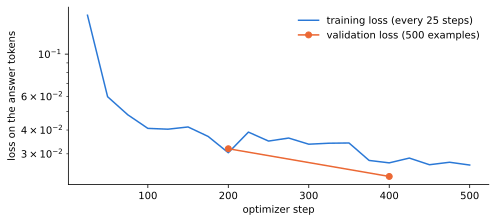

 step  eval_loss
  200   0.031905
  400   0.022827


In [11]:
log = pd.DataFrame(trainer.state.log_history)
fig, ax = plt.subplots(figsize=(7, 3.2))
tr = log.dropna(subset=["loss"])
ev = log.dropna(subset=["eval_loss"])
ax.plot(tr["step"], tr["loss"], color="#2a78d6", label="training loss (every 25 steps)")
ax.plot(ev["step"], ev["eval_loss"], "o-", color="#eb6834", label="validation loss (500 examples)")
ax.set_xlabel("optimizer step")
ax.set_ylabel("loss on the answer tokens")
ax.set_yscale("log")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()
print(ev[["step", "eval_loss"]].to_string(index=False))

## 3. What did training change?

Save the adapter, free the training model, and load the saved adapter on a fresh copy of the base model. That scores
exactly what was saved, which is what you would deploy. Then the 500 test examples are generated again with the
same zero-shot prompt, so any difference comes from the weights.

In [12]:
trainer.model.save_pretrained("adapter")
adapter_mb = sum(os.path.getsize(os.path.join("adapter", f)) for f in os.listdir("adapter")) / 1e6
n_base = n_all - n_trainable
print(f"adapter on disk: {adapter_mb:.1f} MB (the LoRA matrices are kept in float32); base model in fp16: {n_base * 2 / 1e6:,.0f} MB")
print(f"trainable parameters: {n_trainable:,} = {n_trainable / n_base:.2%} of the {n_base:,} base weights")

del trainer, model, base
gc.collect()
torch.cuda.empty_cache()

tuned = PeftModel.from_pretrained(
    AutoModelForCausalLM.from_pretrained(MODEL_ID, torch_dtype=DTYPE, device_map={"": DEVICE}), "adapter").eval()
answers, ms = generate(tuned, tok, [zero_shot(r) for r in test])
scored["fine-tuned"] = score(test, answers)
results["fine-tuned"] = {"runs": scored["fine-tuned"]["runs"].mean(), "exact": scored["fine-tuned"]["exact"].mean(),
                         "ms per example": ms}
print(f"fine-tuned           runs {results['fine-tuned']['runs']:.1%}  exact {results['fine-tuned']['exact']:.1%}  "
      f"{ms:.0f} ms per example (adapter not merged, zero-shot prompt)")

adapter on disk: 73.9 MB (the LoRA matrices are kept in float32); base model in fp16: 3,087 MB
trainable parameters: 18,464,768 = 1.20% of the 1,543,714,304 base weights


fine-tuned           runs 99.0%  exact 71.8%  203 ms per example (adapter not merged, zero-shot prompt)


## 4. What is still wrong?

Every tuned-model answer that is not an exact match is put in one cause by simple rules, tried in this order:

1. **does not run:** SQLite rejects the query;
2. **wrong value or literal:** the query has the same shape as the gold query once literal values are removed;
3. **wrong aggregate, operator or clause:** the multiset of functions, comparison operators and clause keywords
   (`COUNT`, `MAX`, `>`, `ORDER BY`, `JOIN`...) differs;
4. **wrong column or table:** the schema names used differ;
5. **other:** the same parts, written another way.

Exact match is strict, so some of these are correct answers in another form. Question 5 is a clue to how many.

In [13]:
KEYWORDS = {"count", "sum", "avg", "min", "max", "distinct", "order", "group", "by", "desc", "asc", "limit", "having",
            "join", "union", "intersect", "except", "not", "in", "like", "between", "and", "or", "null",
            ">", "<", ">=", "<=", "=", "!=", "<>"}


def shape(sql):
    """The query with literal values removed (lesson 3)."""
    sql = re.sub(r"\"[^\"]*\"|'[^']*'", "V", sql)
    return normalise(re.sub(r"\b\d+(\.\d+)?\b", "N", sql))


def parts(sql):
    return re.findall(r"[a-z_]\w*|<>|!=|>=|<=|[=<>]", shape(sql))


def cause(row, gold, context):
    if row["error"]:
        return "does not run"
    if shape(row["sql"]) == shape(gold):
        return "wrong value or literal"
    got, want = parts(row["sql"]), parts(gold)
    if sorted(t for t in got if t in KEYWORDS) != sorted(t for t in want if t in KEYWORDS):
        return "wrong aggregate, operator or clause"
    schema = set(re.findall(r"[a-z_]\w*", context.lower())) - KEYWORDS
    if {t for t in got if t in schema} != {t for t in want if t in schema}:
        return "wrong column or table"
    return "other"


final = scored["fine-tuned"]
final["cause"] = [cause(row, r["answer"], r["context"]) if not row["exact"] else "exact match"
                  for (_, row), r in zip(final.iterrows(), test)]
print(final["cause"].value_counts().to_string())
print("\nWhy the 'does not run' answers failed:")
print(final[final["cause"] == "does not run"]["error"].str.replace(r"no such column: .*", "no such column", regex=True)
      .str[:50].value_counts().head(5).to_string())

cause
exact match                            359
other                                   61
wrong aggregate, operator or clause     61
wrong value or literal                  14
does not run                             5

Why the 'does not run' answers failed:
error
misuse of aggregate: COUNT()             1
no such table: person_friend             1
near "/": syntax error                   1
unrecognized token: "001_performance"    1
no such column                           1


In [14]:
fails = final[final["cause"] != "exact match"].sample(5, random_state=SEED)
for i, row in fails.iterrows():
    print(f"[{row['cause']}]")
    print("question:", test[i]["question"])
    print("gold    :", test[i]["answer"])
    print("model   :", row["sql"], "\n")

[other]
question: what was the score in 1990
gold    : SELECT score FROM table_name_85 WHERE year = 1990
model   : SELECT score FROM table_name_85 WHERE year = "1990" 

[other]
question: What are the average price and score of wines grouped by appelation?
gold    : SELECT AVG(Price), AVG(Score), Appelation FROM WINE GROUP BY Appelation
model   : SELECT AVG(Price), AVG(Score) FROM WINE GROUP BY Appelation 

[does not run]
question: What is the total number of people who has no friend living in the city of Austin.
gold    : SELECT COUNT(DISTINCT name) FROM PersonFriend WHERE NOT friend IN (SELECT name FROM person WHERE city = 'Austin')
model   : SELECT COUNT(*) FROM person WHERE NOT name IN (SELECT name FROM person_friend WHERE city = 'Austin') AND NOT friend IN (SELECT name FROM person_friend WHERE city = 'Austin') 

[other]
question: How many goals have 28 as the points, and matches greater than 11?
gold    : SELECT COUNT(goals) FROM table_name_56 WHERE points = 28 AND matches > 11
mod

## 5. Is it worth it?

All three systems on the same 500 examples. The ± column is the 95% interval on the exact-match rate,
$1.96\sqrt{p(1-p)/n}$ (lesson 3): differences smaller than that are not evidence.

In [15]:
table = pd.DataFrame(results).T
table["exact ±"] = 1.96 * np.sqrt(table["exact"] * (1 - table["exact"]) / N_TEST)
table["runs"] = (table["runs"] * 100).round(1)
table["exact"] = (table["exact"] * 100).round(1)
table["exact ±"] = (table["exact ±"] * 100).round(1)
table["ms per example"] = table["ms per example"].round(0)
print(table[["runs", "exact", "exact ±", "ms per example"]].rename(
    columns={"runs": "runs, %", "exact": "exact match, %", "exact ±": "exact ±, points"}).to_string())
print(f"\ntraining: {N_TRAIN:,} examples, {train_secs / 60:.0f} minutes, peak {peak_alloc:.1f} GB, "
      f"adapter {adapter_mb:.0f} MB, {n_trainable / 1e6:.0f}M trainable parameters")

                     runs, %  exact match, %  exact ±, points  ms per example
baseline, zero-shot     96.2            58.4              4.3           114.0
baseline, 3-shot        96.0            59.4              4.3           159.0
fine-tuned              99.0            71.8              3.9           203.0

training: 8,000 examples, 15 minutes, peak 9.9 GB, adapter 74 MB, 18M trainable parameters


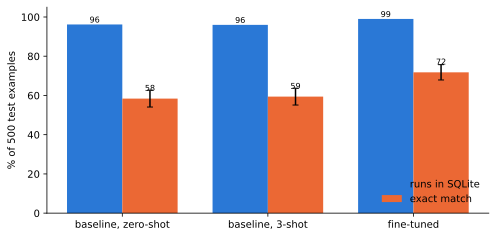

In [16]:
fig, ax = plt.subplots(figsize=(7, 3.4))
x = np.arange(len(table))
w = 0.38
ax.bar(x - w / 2, table["runs"], w, color="#2a78d6", label="runs in SQLite")
ax.bar(x + w / 2, table["exact"], w, yerr=table["exact ±"], capsize=3, color="#eb6834", label="exact match")
for i, (a, b) in enumerate(zip(table["runs"], table["exact"])):
    ax.text(i - w / 2, a + 1, f"{a:.0f}", ha="center", fontsize=8)
    ax.text(i + w / 2, b + 4, f"{b:.0f}", ha="center", fontsize=8)
ax.set_xticks(x)
ax.set_xticklabels(table.index)
ax.set_ylabel("% of 500 test examples")
ax.set_ylim(0, 105)
ax.legend(frameon=False, loc="lower right")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

## 6. What do we keep?

The adapter was saved to `./adapter` in section 3, and section 3 scored it after loading it back, so the saved files
are the ones measured. It holds only the LoRA matrices and their configuration; it is loaded on top of the original
Qwen2.5-1.5B-Instruct. In Colab, download it from the Files panel on the left.

In [17]:
for f in sorted(os.listdir("adapter")):
    print(f"{os.path.getsize(os.path.join('adapter', f)) / 1e6:8.2f} MB  {f}")
print(json.load(open("adapter/adapter_config.json"))["base_model_name_or_path"])

    0.01 MB  README.md
    0.00 MB  adapter_config.json
   73.91 MB  adapter_model.safetensors
Qwen/Qwen2.5-1.5B-Instruct


## Read the result

- **Measure the baseline you would otherwise ship.** The table compares training against a prompt with three examples,
  not only against the model with no help.
- **Two metrics, two meanings.** "Runs" is a floor on quality that needs no gold answer; "exact" is strict and
  misses correct queries written differently. Neither is execution accuracy, because the tables are empty.
- **The loss was on the answer only,** as the label counts proved, and the validation loss shows whether the run was
  still improving when it stopped.
- **Read the failures, not only the score.** The error table says what the next lesson's data or method must fix.
- **The cost is small:** an adapter of a few tens of megabytes, trained in minutes on a free GPU.

The lesson explains each result and the companies that learned the same lessons:
[Your first fine-tune: SFT with LoRA](https://docs.recohut.com/courses/llm-fine-tuning/2-train/04-sft-with-lora).